# Predviđanje mesečne kirije stanova u gradovima Poljske

**Izvor:** [Apartment Prices in Poland](https://www.kaggle.com/datasets/krzysztofjamroz/apartment-prices-in-poland) (Kaggle, Apache 2.0). Oglasi za izdavanje stanova u 15 najvećih gradova Poljske, mesečni snimci nov. 2023 – jun 2024, dopunjeni podacima iz OpenStreetMap-a.

## 1. Definisanje problema

- **Jedan primer:** jedan stan oglašen za izdavanje.
- **Cilj:** mesečna kirija u PLN (`price`), **regresija**.
- **Korisnost:** procena realne kirije za novi oglas (za stanodavce, stanare i portale) i uvid u to koliko lokacija i gradska infrastruktura utiču na cenu.
- **Ulazi:** karakteristike stana (kvadratura, sobe, sprat, godina gradnje, opremljenost) i okoline (grad, udaljenost od centra, broj i udaljenost obližnjih sadržaja). Svi su poznati u trenutku objave oglasa.
- `id` je samo identifikator oglasa, a `ownership` ima istu vrednost u svim redovima; nijedan od njih se ne koristi kao ulaz.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

DATA_DIR = Path("../data") if Path("../data").exists() else Path("data")
files = sorted(DATA_DIR.glob("apartments_rent_pl_*.csv"))
raw = pd.concat(
    [pd.read_csv(f).assign(snapshot=f.stem[-7:]) for f in files],
    ignore_index=True,
)
print(raw.shape, "| jedinstvenih stanova:", raw["id"].nunique())
raw.head(3)

(70847, 29) | jedinstvenih stanova: 37941


,id,city,type,squareMeters,rooms,floor,floorCount,buildYear,latitude,longitude,...,ownership,buildingMaterial,condition,hasParkingSpace,hasBalcony,hasElevator,hasSecurity,hasStorageRoom,price,snapshot
0,2a1a6db97ff122d6bc148abb6f0e498a,szczecin,blockOfFlats,52.0,2.0,3.0,3.0,2008.0,53.460535,14.545416,...,condominium,brick,NaN,yes,yes,no,no,no,3500,2023_11
1,5a0cb42c088eadf75aa98a4118640048,szczecin,blockOfFlats,57.0,3.0,NaN,10.0,1976.0,53.440955,14.566024,...,condominium,NaN,premium,no,yes,yes,no,no,3000,2023_11
2,996722490efcb4b34d48bb84a9a72838,szczecin,NaN,43.4,2.0,3.0,4.0,NaN,53.435746,14.560764,...,condominium,NaN,NaN,no,yes,no,no,no,1900,2023_11


### 1.1 Jedan red po stanu

Isti oglas se pojavljuje u više mesečnih snimaka. Ako bi isti stan završio i u trening i u test skupu, ocena bi bila preoptimistična (curenje podataka). Zato se za svaki stan zadržava **prvo pojavljivanje**, tj. cena u trenutku objave oglasa.

In [2]:
print(raw.groupby("id").size().value_counts().sort_index().rename("broj snimaka po stanu").to_frame().T)

df = (raw.sort_values("snapshot")
         .groupby("id", as_index=False).head(1)
         .drop(columns=["ownership"])
         .reset_index(drop=True))
print(df.shape)

                           1     2     3     4    5    6    7    8
broj snimaka po stanu  20947  8344  5190  1671  802  336  276  375


(37941, 28)

## 2. Podela podataka

Model bi se koristio za procenu kirije **novih oglasa**, pa test skup čine stanovi koji su se prvi put pojavili u poslednja dva meseca (maj i jun 2024). Trening skup čine svi ranije objavljeni stanovi. Svaki stan je samo u jednom skupu.

In [3]:
is_test = df["snapshot"] >= "2024_05"
train, test = df[~is_test].copy(), df[is_test].copy()
print(f"train: {len(train)}  test: {len(test)}  ({is_test.mean():.1%})")

train: 28579  test: 9362  (24.7%)


## 3. Eksplorativna analiza (samo trening skup)

count    28579.0
mean      3741.0
std       2232.0
min        346.0
25%       2500.0
50%       3000.0
75%       4300.0
max      23000.0
Name: price, dtype: float64


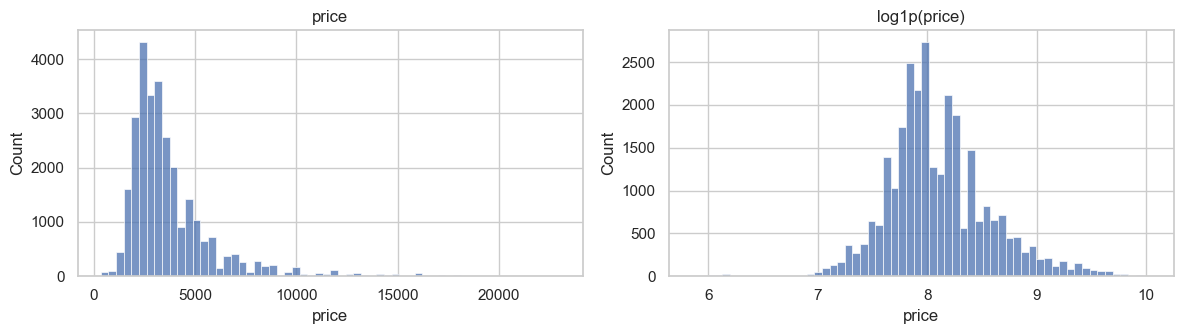

In [4]:
y = train["price"]
print(y.describe().round(0))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(y, bins=60, ax=axes[0]).set_title("price")
sns.histplot(np.log1p(y), bins=60, ax=axes[1]).set_title("log1p(price)")
plt.tight_layout(); plt.show()

In [5]:
missing = train.isna().mean().loc[lambda s: s > 0].sort_values(ascending=False)
missing.round(3).to_frame("udeo NaN")

,udeo NaN
condition,0.737
buildingMaterial,0.429
buildYear,0.286
type,0.251
floor,0.124
hasElevator,0.056
floorCount,0.020
collegeDistance,0.013
restaurantDistance,0.002
pharmacyDistance,0.001


In [6]:
city_stats = train.groupby("city")["price"].agg(["size", "median"]).sort_values("median", ascending=False)
city_stats.T

city,warszawa,krakow,wroclaw,gdansk,gdynia,szczecin,rzeszow,lublin,poznan,katowice,radom,bialystok,lodz,bydgoszcz,czestochowa
size,11254.0,5375.0,2708.0,1587.0,634.0,567.0,219.0,457.0,1701.0,1042.0,85.0,174.0,1991.0,533.0,252.0
median,4200.0,3000.0,2950.0,2900.0,2700.0,2500.0,2490.0,2400.0,2400.0,2200.0,2100.0,2000.0,2000.0,1950.0,1900.0


In [7]:
num_cols = train.select_dtypes("number").columns
train[num_cols].corr(method="spearman")["price"].drop("price").sort_values().round(2).to_frame("Spearman sa price").T

,restaurantDistance,clinicDistance,collegeDistance,kindergartenDistance,pharmacyDistance,schoolDistance,postOfficeDistance,centreDistance,buildYear,latitude,floor,floorCount,poiCount,longitude,rooms,squareMeters
Spearman sa price,-0.24,-0.21,-0.09,-0.07,-0.06,-0.04,-0.02,0.03,0.06,0.09,0.09,0.15,0.23,0.44,0.59,0.66


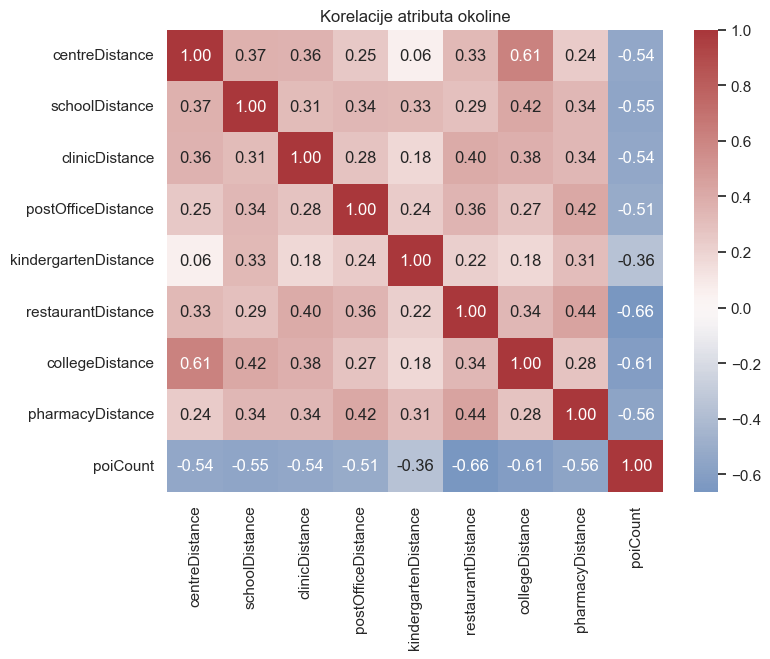

In [8]:
dist_cols = ["centreDistance", "schoolDistance", "clinicDistance", "postOfficeDistance",
             "kindergartenDistance", "restaurantDistance", "collegeDistance", "pharmacyDistance", "poiCount"]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(train[dist_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Korelacije atributa okoline")
plt.show()

In [9]:
# Sumnjive vrednosti
print("Kirija < 800 PLN:", (train["price"] < 800).sum())
print("Kvadratura < 15 m2:", (train["squareMeters"] < 15).sum(), "| > 150 m2:", (train["squareMeters"] > 150).sum())
print("floor > floorCount:", (train["floor"] > train["floorCount"]).sum())
train.nsmallest(5, "price")[["city", "squareMeters", "rooms", "price"]]

Kirija < 800 PLN: 84
Kvadratura < 15 m2: 0 | > 150 m2: 0
floor > floorCount: 0


,city,squareMeters,rooms,price
14602,katowice,30.36,1.0,346
14494,katowice,28.41,1.0,347
14520,katowice,32.79,1.0,371
14479,katowice,32.50,1.0,380
14590,katowice,35.00,2.0,399


### 3.1 Zaključci i odluke za pripremu

| Nalaz | Odluka |
|---|---|
| Kirija je asimetrična (medijana 3.000, maksimum 23.000 PLN). | Model se uči na `log1p(price)`; glavna metrika je **MAE u PLN**. Baseline je medijana trening skupa. |
| Najjači pojedinačni atributi su kvadratura (ρ = 0.66) i broj soba (0.59). Velike razlike po gradovima: medijana od 1.900 (Częstochowa) do 4.200 PLN (Varšava). | `city` se kodira one-hot. |
| Udaljenost od centra na nivou cele zemlje skoro ne utiče (ρ = 0.03), ali unutar grada da (medijana ρ ≈ −0.12, a za cenu po m² ≈ −0.18). Efekat je prikriven razlikama između gradova. | Zadržava se; modeli sa interakcijama (stabla) to mogu da iskoriste. |
| Udaljenosti do sadržaja su međusobno korelisane (ρ do 0.6). | Prirodan kandidat za **PCA** / selekciju atributa (odeljak o redukciji). |
| Nedostajuće vrednosti: `condition` 74%, `buildingMaterial` 43%, `buildYear` 29%, `type` 25%, `floor` 12%. | Kategorički: NaN kao posebna kategorija ("unknown"). Numerički: medijana + indikator nedostajanja. Sve u `Pipeline`-u. |
| 84 oglasa imaju kiriju ispod 800 PLN, od toga 82 u Katovicama (npr. 30 m² za 346 PLN). To su verovatno greške ili cena po krevetu. | Uklanjaju se samo iz trening skupa; test ostaje netaknut. |